# Sankeys completos das MIPs brasileiras de 20 e 67 atividades

MIP do IBGE de 2015, produção nacional e demanda final incluindo exportações. Não há calibração de fluxos, corte por relevância, supressão da diagonal ou atribuição de emissões importadas. A matriz ambiental é $F=\operatorname{diag}(\varphi)L\operatorname{diag}(y)$, com $c=F\mathbf1$ e $u^T=\mathbf1^TF$.

**Os fluxos econômicos são os oficiais; as emissões são estimadas.** Mantemos os coeficientes de Sanguinet e Azzoni (2024) adotados no projeto, interpolados entre 2011 e 2018. A compatibilidade monetária usa fator 1, sem deflação efetiva: os valores ambientais não são um inventário oficial. No nível 20, agregamos as emissões diretas das 67 atividades e dividimos pela produção de cada grupo. F é calculada no sistema monetário oficial de cada nível; agregar F de 67 para 20 não é equivalente a esse procedimento.

A cor de círculos não é utilizada aqui: são somente dois Sankeys independentes, com barras e faixas. As barras de produção e demanda usam uma escala comum de cores nos dois documentos. Todas as parcelas positivas de F, inclusive a diagonal, são desenhadas; zeros estruturais não geram faixas.

In [1]:
from pathlib import Path
import json,textwrap
import numpy as np
import pandas as pd
from IPython.display import display
from redes import dados,modelo,mip

meta20=dados.entrada("mip_ibge_2015_20")
dados.check_sha256(dados.RAIZ_PROJETO/meta20["arquivo"],meta20["sha256"])
t20=pd.read_excel(dados.RAIZ_PROJETO/meta20["arquivo"],sheet_name=None,header=None,engine="xlrd")
t67=dados.carregar_matriz_67("mip_ibge_2015_67")
codigos20=t20["14"].iloc[5:25,0].astype(str).str.strip().tolist()
nomes20=t20["14"].iloc[5:25,1].astype(str).str.strip().tolist()
assert codigos20==list("ABCDEFGHIJKLMNOPQRST")
x67=modelo.calcular_producao_bruta_67(t67)
Z67=modelo.calcular_matriz_transacoes_intersetoriais_67(t67)
y67=mip.carregar_demanda_final_nacional_67(t67)
L67=mip.carregar_inversa_leontief_ibge_67(t67)
codigos67=x67.index.tolist()
nomes67=t67["14"].iloc[5:72,1].astype(str).str.strip().tolist()
phi0=dados.carregar_coeficientes_co2("sanguinet_azzoni_2011")[2011]
phi1=dados.carregar_coeficientes_co2("sanguinet_azzoni_2018")[2018]
assert phi0.index.equals(phi1.index)
phi67=pd.Series((phi0+4/7*(phi1-phi0)).to_numpy(),index=x67.index)
c67=phi67*x67
F67=L67.mul(phi67,axis=0).mul(y67,axis=1)
u67=F67.sum(axis=0)
np.testing.assert_allclose(Z67.sum(axis=1)+y67,x67,rtol=1e-12,atol=1e-7)
np.testing.assert_allclose(L67,np.linalg.inv(np.eye(67)-Z67.to_numpy()/x67.to_numpy()[None,:]),rtol=1e-10,atol=1e-12)
np.testing.assert_allclose(F67.sum(axis=1),c67,rtol=1e-12,atol=1e-7)
np.testing.assert_allclose(u67.sum(),c67.sum(),rtol=1e-12)
assert (F67.to_numpy()>=0).all() and (y67>0).all()


SHA-256 verificado: Matriz_de_Insumo_Produto_2015_Nivel_20.xls.original
SHA-256 verificado: Matriz_de_Insumo_Produto_2015_Nivel_67.xls.original
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2011.csv
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2018.csv


## 1. Sistema de 20 atividades e correspondência com o nível 67

As seções A–T correspondem aos 20 grupos publicados. O mapeamento é explícito. Conferimos cobertura sem repetição e coincidência das produções agregadas com a Tabela 01 de nível 20. Extraímos D, U, x e a demanda final sem alterar valores; a matriz A e a inversa L são conferidas contra as Tabelas 14 e 15.

In [2]:
grupos20={
 "A":["0191","0192","0280"],"B":["0580","0680","0791","0792"],
 "C":[c for c in x67.index if 10<=int(c[:2])<=33],
 "D":["3500"],"E":["3680"],"F":["4180"],"G":["4580"],
 "H":["4900","5000","5100","5280"],"I":["5500","5600"],
 "J":["5800","5980","6100","6280"],"K":["6480"],"L":["6800"],
 "M":["6980","7180","7380"],"N":["7700","7880","8000"],"O":["8400"],
 "P":["8591","8592"],"Q":["8691","8692"],"R":["9080"],"S":["9480"],"T":["9700"],
}
cobertura=[c for cs in grupos20.values() for c in cs]
assert len(cobertura)==len(set(cobertura))==67 and set(cobertura)==set(codigos67)
assert [str(c).splitlines()[0].strip() for c in t20["14"].iloc[3,2:22]]==codigos20
V20=t20["01"].iloc[5:25,7:27].to_numpy(float)
D20=t20["13"].iloc[5:25,2:22].to_numpy(float)
U20=t20["03"].iloc[5:25,3:23].to_numpy(float)
x20=V20.sum(axis=0)
Z20=D20@U20
y20=D20@t20["03"].iloc[5:25,30].to_numpy(float)
A20=Z20/x20[None,:]
L20=t20["15"].iloc[5:25,2:22].to_numpy(float)
np.testing.assert_allclose(D20,V20.T/V20.sum(axis=1)[None,:],rtol=1e-12,atol=1e-12)
np.testing.assert_allclose([x67.loc[grupos20[c]].sum() for c in codigos20],x20,rtol=0,atol=1e-8)
np.testing.assert_allclose(Z20.sum(axis=1)+y20,x20,rtol=1e-12,atol=1e-7)
np.testing.assert_allclose(A20,t20["14"].iloc[5:25,2:22].to_numpy(float),rtol=1e-10,atol=1e-12)
np.testing.assert_allclose(L20,np.linalg.inv(np.eye(20)-A20),rtol=1e-10,atol=1e-12)
c20=np.array([c67.loc[grupos20[c]].sum() for c in codigos20])
phi20=c20/x20
F20=pd.DataFrame(phi20[:,None]*L20*y20[None,:],index=codigos20,columns=codigos20)
u20=F20.sum(axis=0).to_numpy()
np.testing.assert_allclose(F20.sum(axis=1),c20,rtol=1e-12,atol=1e-7)
np.testing.assert_allclose(u20.sum(),c20.sum(),rtol=1e-12)
np.testing.assert_allclose(c20.sum(),c67.sum(),rtol=1e-12)
assert (F20.to_numpy()>=0).all() and (y20>0).all()
for F,c,u in [(F20,c20,u20),(F67,c67,u67)]:
    np.testing.assert_allclose(F.sum(axis=1),np.asarray(c),rtol=1e-12,atol=1e-7)
    np.testing.assert_allclose(F.sum(axis=0),np.asarray(u),rtol=1e-12,atol=1e-7)
    print(F.shape[0],"atividades:",int((F.to_numpy()>0).sum()),"faixas positivas; total",F.to_numpy().sum(),"Gg CO₂")


20 atividades: 362 faixas positivas; total 683696.0414285716 Gg CO₂
67 atividades: 4357 faixas positivas; total 683696.0414285713 Gg CO₂


## 2. Geometria proporcional e legibilidade

Cada faixa tem altura proporcional a F_ij; as barras representam as somas c e u. Os fatores geométricos são lineares, sem piso. Os setores têm a mesma ordem e o mesmo centro vertical nas duas margens. Reservamos espaço em branco suficiente para seus nomes completos, quebrados em linhas, sem aumentar a altura das barras pequenas.

A altura de cada faixa é `F_ij / soma(F) * altura_emissoes`. O fator `altura_emissoes` é escolhido por bisseção para caber na página; as alturas das barras continuam estritamente proporcionais aos valores. A altura da **faixa reservada ao rótulo** usa o máximo entre as duas barras e o texto; esse espaço em branco não representa emissões. Espaços entre faixas reservadas também não são fluxos.

A função de desenho abaixo é usada para os dois níveis. As contas e o mapeamento permanecem explícitos nas seções anteriores. Documentos de tamanhos diferentes têm fatores físicos de espessura diferentes; as cores usam a mesma normalização e unidade nos dois.

In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.path import Path as Caminho
from matplotlib.patches import PathPatch,Rectangle

paleta=plt.get_cmap("viridis_r")
valores_cores=np.r_[c20,u20,c67.to_numpy(),u67.to_numpy()]
norma=Normalize(vmin=valores_cores.min(),vmax=valores_cores.max())

def desenhar_sankey(F,nomes,figsize,fonte,largura_texto):
    """Desenha todas as parcelas positivas, com espaços livres para os nomes."""
    valores=F.to_numpy();c=valores.sum(axis=1);u=valores.sum(axis=0)
    total=valores.sum();n=len(c)
    textos=[textwrap.fill(str(codigo)+"  "+nome,width=largura_texto,break_long_words=False,
                         break_on_hyphens=False) for codigo,nome in zip(F.index,nomes)]
    largura,altura=figsize
    altura_eixo=.85*altura
    altura_util=altura_eixo-.8
    alturas_texto=np.array([(texto.count("\n")+1)*fonte/72*1.25+.025 for texto in textos])
    gap=.08 if n==20 else .045
    assert alturas_texto.sum()+(n-1)*gap<altura_util,"A página precisa de mais altura para os rótulos."
    # Ajusta somente o fator físico comum, sem piso na altura das barras/faixas.
    baixo,alto=0,altura_util
    for _ in range(80):
        fator=(baixo+alto)/2
        alturas_faixas=np.maximum(np.maximum(c,u)/total*fator,alturas_texto)
        if alturas_faixas.sum()+(n-1)*gap>altura_util:alto=fator
        else:baixo=fator
    altura_emissoes=baixo
    hc=c/total*altura_emissoes;hu=u/total*altura_emissoes
    alturas_faixas=np.maximum(np.maximum(hc,hu),alturas_texto)
    topos_faixas=altura_eixo-.6-np.r_[0,np.cumsum(alturas_faixas[:-1])+gap*np.arange(1,n)]
    centros=topos_faixas-alturas_faixas/2
    topos_c=centros+hc/2;topos_u=centros+hu/2
    cursores_c=topos_c.copy();cursores_u=topos_u.copy()
    fig=plt.figure(figsize=figsize)
    ax=fig.add_axes([0,.11,1,.85])
    xe,xd,barra=.31*largura,.69*largura,.12
    x0,x1=xe+barra,xd
    controle1=x0+.42*(x1-x0);controle2=x1-.42*(x1-x0)
    faixas=0
    for i in range(n):
        for j in range(n):
            valor=valores[i,j]
            if valor==0:continue
            h=valor/total*altura_emissoes;yc,yu=cursores_c[i],cursores_u[j]
            vertices=[(x0,yc),(controle1,yc),(controle2,yu),(x1,yu),
                (x1,yu-h),(controle2,yu-h),(controle1,yc-h),(x0,yc-h),(x0,yc)]
            codigos=[Caminho.MOVETO,Caminho.CURVE4,Caminho.CURVE4,Caminho.CURVE4,
                Caminho.LINETO,Caminho.CURVE4,Caminho.CURVE4,Caminho.CURVE4,Caminho.CLOSEPOLY]
            ax.add_patch(PathPatch(Caminho(vertices,codigos),facecolor=paleta(norma(c[i])),
                alpha=.42,edgecolor="none",linewidth=0))
            cursores_c[i]-=h;cursores_u[j]-=h;faixas+=1
    np.testing.assert_allclose(cursores_c,topos_c-hc,atol=1e-10)
    np.testing.assert_allclose(cursores_u,topos_u-hu,atol=1e-10)
    assert faixas==np.count_nonzero(valores)
    for totais,alturas,topos,x,lado in [(c,hc,topos_c,xe,"esquerda"),(u,hu,topos_u,xd,"direita")]:
        for i,texto in enumerate(textos):
            ax.add_patch(Rectangle((x,topos[i]-alturas[i]),barra,alturas[i],
                facecolor=paleta(norma(totais[i])),edgecolor="black",linewidth=.35))
            ax.text(x-.12 if lado=="esquerda" else x+barra+.12,centros[i],texto,
                ha="right" if lado=="esquerda" else "left",va="center",fontsize=fonte,
                fontfamily="DejaVu Serif",linespacing=1.15)
    assert len(ax.patches)==faixas+2*n
    ax.text(xe,altura_eixo-.2,"Setor emissor",ha="center",fontsize=fonte+2,fontfamily="DejaVu Serif")
    ax.text(xd+barra,altura_eixo-.2,"Demanda Final",ha="center",fontsize=fonte+2,fontfamily="DejaVu Serif")
    ax.set(xlim=(0,largura),ylim=(0,altura_eixo));ax.axis("off")
    ax_cor=fig.add_axes([.38,.067,.24,.008])
    cb=fig.colorbar(ScalarMappable(norm=norma,cmap=paleta),cax=ax_cor,
        orientation="horizontal",ticks=[norma.vmin,norma.vmax])
    cb.ax.set_xticklabels(["Menores","Maiores"],fontsize=fonte,fontfamily="DejaVu Serif")
    cb.ax.tick_params(length=0,pad=3);cb.outline.set_visible(False)
    cb.set_label("Emissões de CO₂ (Gg)",fontsize=fonte+1,fontfamily="DejaVu Serif",labelpad=4)
    fig.text(.5,.018,"Altura das barras e espessura das faixas: emissões de CO₂ (Gg)",
        ha="center",fontsize=fonte,fontfamily="DejaVu Serif")
    return fig,faixas,altura_emissoes


## 3. Exportação dos dois documentos e das matrizes completas

A3 vertical para 20 atividades e A2 vertical para 67. Os códigos nas margens são os oficiais do IBGE, acompanhados dos nomes completos. A publicação em vetor permite ampliar as parcelas muito finas; o PNG serve como prévia. Os CSV preservam a precisão numérica. O total ambiental é igual nos dois sistemas, embora a distribuição pela demanda possa mudar com a agregação.

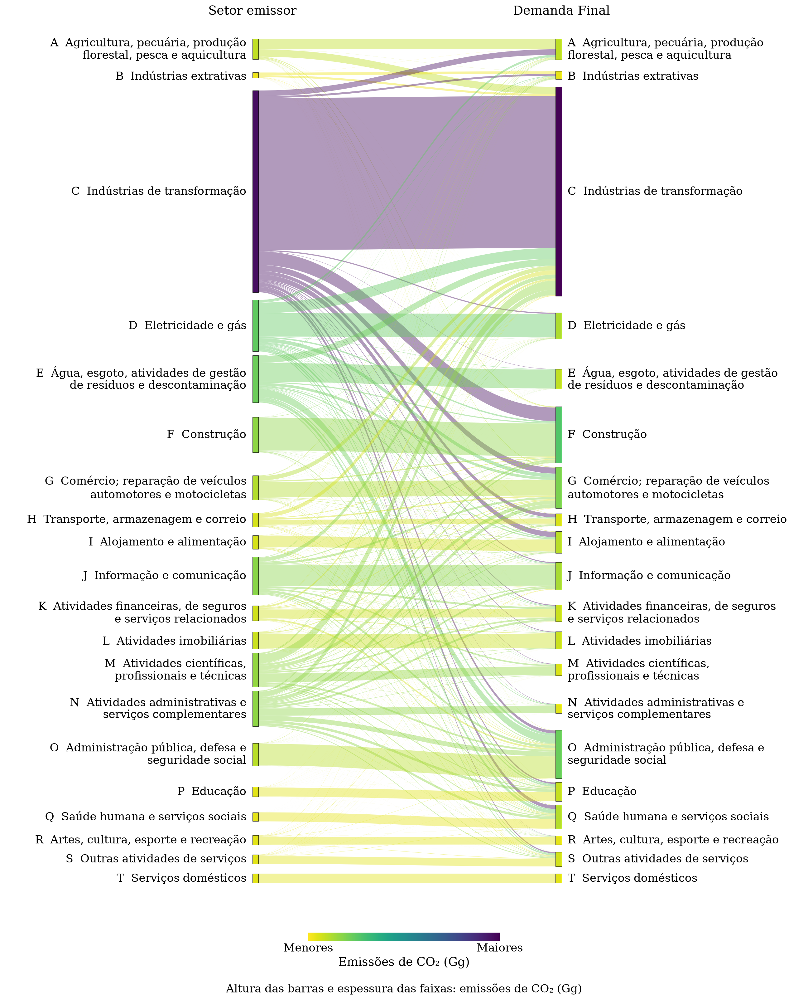

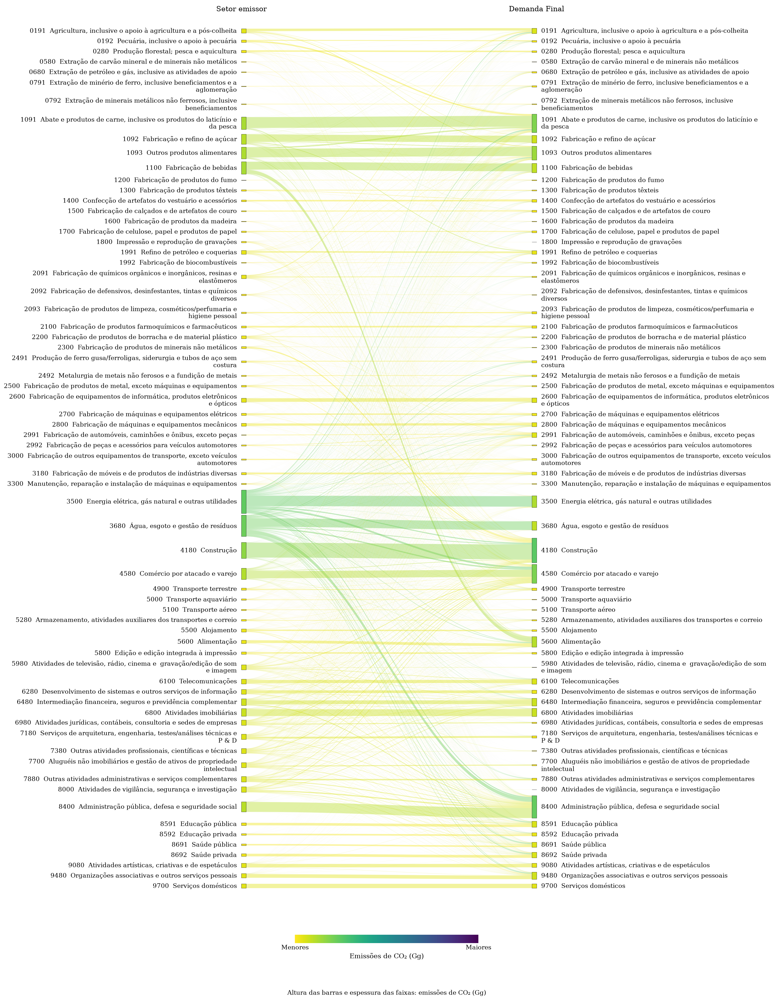

In [4]:
pasta=Path("outputs/sankeys_mip20_67");pasta.mkdir(parents=True,exist_ok=True)
fig20,faixas20,fator20=desenhar_sankey(F20,nomes20,(16,21),16,38)
for ext in ["pdf","svg","png"]:fig20.savefig(pasta/f"sankey_mip20.{ext}",dpi=160,bbox_inches="tight")
display(fig20);plt.close(fig20)
fig67,faixas67,fator67=desenhar_sankey(F67,nomes67,(20,27.5),11.5,70)
for ext in ["pdf","svg","png"]:fig67.savefig(pasta/f"sankey_mip67.{ext}",dpi=160,bbox_inches="tight")
display(fig67);plt.close(fig67)
F20.to_csv(pasta/"F_20.csv");F67.to_csv(pasta/"F_67.csv")
pd.DataFrame({"atividade":nomes20,"x_r_milhoes":x20,"y_r_milhoes":y20,
    "phi_gg_por_r_milhao":phi20,"c_gg":c20,"u_gg":u20},index=codigos20).to_csv(pasta/"contas_20.csv")
pd.DataFrame({"atividade":nomes67,"x_r_milhoes":x67.to_numpy(),"y_r_milhoes":y67.to_numpy(),
    "phi_gg_por_r_milhao":phi67.to_numpy(),"c_gg":c67.to_numpy(),"u_gg":u67.to_numpy()},index=codigos67).to_csv(pasta/"contas_67.csv")
pd.DataFrame([{"atividade67":c,"grupo20":g} for g,cs in grupos20.items() for c in cs]).to_csv(pasta/"correspondencia_67_20.csv",index=False)
proveniencia={"entradas":[dados.entrada(k) for k in ["mip_ibge_2015_20","mip_ibge_2015_67","sanguinet_azzoni_2011","sanguinet_azzoni_2018"]],
    "faixas20":faixas20,"faixas67":faixas67,"total_gg":float(c67.sum()),
    "limites_cores_gg":[float(norma.vmin),float(norma.vmax)],
    "altura_emissoes_polegadas":{"20":fator20,"67":fator67}}
(pasta/"proveniencia.json").write_text(json.dumps(proveniencia,ensure_ascii=False,indent=2),encoding="utf-8")
print("Faixas desenhadas:",faixas20,"e",faixas67,"; total conservado:",c67.sum(),"Gg de CO₂")
